# df_analysis.csv 반도체 공정 데이터 분석

1. 데이터 로드 및 기본 점검
2. 라벨(Defect / 두께정상 / CD정상) 정의 확인
3. 변수 정리 (상수·중복 제거)
4. 단변량 관계 분석 (상관, 그룹 비교)
5. Target 회귀 모델 & 변수 중요도
6. Defect 분류 모델 (Target 제외)
7. 해석 가능한 규칙 추출 (Decision Tree, Partial Dependence)
8. 고위험 공정 조건 & 시각화

## 1. 데이터 로드 및 기본 점검
파일은 CP949 인코딩입니다.

In [1]:
import warnings
import numpy as np
import pandas as pd
from scipy import stats

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', '{:,.4f}'.format)   # 지수 표기 대신 천 단위 콤마 + 소수점 4자리 (표시만, 데이터는 원본 유지)

df = pd.read_csv('../data/df_analysis.csv', encoding='cp949')
print(f'데이터 크기: {df.shape[0]:,}행 × {df.shape[1]}열')
df.head()

데이터 크기: 1,664행 × 45열


,type,Temp_OXid,Vapor,ppm,Pressure,Oxid_time,thickness,resist_target,N2_HMDS,pressure_HMDS,temp_HMDS,temp_HMDS_bake,time_HMDS_bake,spin1,spin2,spin3,photoresist_bake,temp_softbake,time_softbake,Line_CD,UV_type,Wavelength,Resolution,Energy_Exposure,Thin F4,Thin F3,Thin F2,Thin F1,Temp_Etching,Source_Power,Selectivity,Flux60s,Flux90s,Flux160s,Flux480s,Flux840s,input_Energy,Temp_implantation,Furance_Temp,RTA_Temp,Target,Temp_Oxid,Defect,두께정상,CD정상
0,dry,"1,214.3100",O2,26.6900,0.2030,120,713.1320,1.4699,17.3670,15.0060,20.0010,200.5510,90.0010,502.3910,"4,017.1440","4,903.6110",5.0200,91.9180,30.0050,41.6760,I,365,505.3880,109.6280,340,"1,522.0000",3644,"5,732.0000",72.6510,52.1030,1.0300,"15,000,000,000,000,000.0000","132,000,000,000,000,000.0000","647,000,000,000,000,000.0000","301,000,000,000,000,000.0000","600,000,000,000,000,000.0000","30,795.9340",103.4330,854,154,141,866.3370,0,정상,정상
1,dry,978.1110,O2,30.8600,0.2170,137,714.2950,0.8658,16.0900,15.0590,19.9930,199.8350,89.9990,507.1830,"4,072.9130","4,979.0820",4.9370,90.9760,30.0050,53.6120,H,405,541.7320,104.9170,265,"1,513.0000",3631,"5,729.0000",70.2670,52.0040,1.0380,"11,100,000,000,000,000.0000","43,700,000,000,000,000.0000","1,040,000,000,000,000,000.0000","303,000,000,000,000,000.0000","600,000,000,000,000,000.0000","32,135.6180",105.5520,895,156,55,866.3370,0,정상,정상
2,dry,"1,176.0200",O2,31.0700,0.2180,116,710.1140,0.9048,19.0260,14.9300,19.9950,202.1180,90.0010,501.2860,"4,084.9390","5,031.9890",4.8880,91.9690,30.0060,47.5980,I,365,532.2000,106.6320,411,"1,568.0000",3653,"5,729.0000",71.2310,50.8460,1.0050,"10,400,000,000,000,000.0000","15,100,000,000,000,000.0000","647,000,000,000,000,000.0000","298,000,000,000,000,000.0000","600,000,000,000,000,000.0000","31,057.8950",102.5980,898,152,96,866.3370,0,정상,정상
3,dry,933.4430,O2,31.0400,0.1960,143,710.6170,0.4220,18.8910,14.9470,20.0040,194.6680,90.0000,503.3960,"4,045.0780","4,969.3160",4.9330,91.4580,30.0010,32.8430,G,436,537.7290,108.7850,328,"1,326.0000",3661,"5,718.0000",71.2950,51.6650,1.0250,"8,890,000,000,000,000.0000","102,000,000,000,000,000.0000","341,000,000,000,000,000.0000","300,000,000,000,000,000.0000","600,000,000,000,000,000.0000","32,140.5660",102.9630,879,155,105,866.3370,0,정상,정상
4,wet,"1,140.6000",H2O,31.3700,0.2150,76,711.6320,1.7014,13.7880,14.8200,19.9980,202.1920,90.0000,501.4230,"4,010.1760","5,092.4070",5.0500,94.7230,29.9880,57.3700,H,405,522.1430,109.9130,219,"1,451.0000",3637,"5,729.0000",72.9830,50.7870,1.0380,"16,700,000,000,000,000.0000","78,800,000,000,000,000.0000","726,000,000,000,000,000.0000","302,000,000,000,000,000.0000","600,000,000,000,000,000.0000","31,986.0090",101.4190,882,155,79,866.3370,0,정상,비정상


In [2]:
print(f'결측치 합계 : {df.isna().sum().sum():,}')
print(f'중복 행     : {df.duplicated().sum():,}')
print()
print(f'[컬럼 타입별 개수]')
print(df.dtypes.value_counts().to_string())
print()
print(f'[범주형 변수 분포]')
for c in ['type', 'Vapor', 'UV_type', '두께정상', 'CD정상']:
    vc = df[c].value_counts()
    detail = ', '.join(f'{k} {v:,}개 ({v / len(df):.1%})' for k, v in vc.items())
    print(f'  {c:<8s}: {detail}')

결측치 합계 : 0
중복 행     : 0

[컬럼 타입별 개수]
float64    32
int64       8
str         5

[범주형 변수 분포]
  type    : dry 970개 (58.3%), wet 694개 (41.7%)
  Vapor   : O2 970개 (58.3%), H2O 694개 (41.7%)
  UV_type : G 613개 (36.8%), H 554개 (33.3%), I 497개 (29.9%)
  두께정상    : 정상 1,515개 (91.0%), 비정상 149개 (9.0%)
  CD정상    : 정상 1,372개 (82.5%), 비정상 292개 (17.5%)


In [3]:
desc = df.describe().T
desc['count'] = desc['count'].astype(int)
desc['nunique'] = df.nunique()
desc['cv%'] = desc['std'] / desc['mean'] * 100

# count·nunique 는 정수로 표시
display(desc)

,count,mean,std,min,25%,50%,75%,max,nunique,cv%
Temp_OXid,1664,"1,067.9252",150.1664,862.0110,888.4198,"1,071.6750","1,190.9800","1,311.2300",1616,14.0615
ppm,1664,33.3827,8.1218,21.0700,25.5300,33.6000,39.5100,49.9100,496,24.3295
Pressure,1664,0.2108,0.0092,0.1800,0.2040,0.2120,0.2170,0.2290,46,4.3842
Oxid_time,1664,99.0469,72.6014,8.0000,31.0000,86.0000,148.0000,291.0000,197,73.3001
thickness,1664,711.1780,7.8135,681.4350,707.0610,711.7125,715.5640,737.4020,825,1.0987
resist_target,1664,1.1920,0.4156,0.0544,0.8824,1.1138,1.4891,2.3943,830,34.8621
N2_HMDS,1664,16.0714,2.2415,9.4970,14.7037,16.3090,17.3670,23.5730,777,13.9473
pressure_HMDS,1664,15.0035,0.0778,14.7760,14.9510,15.0030,15.0560,15.2810,303,0.5185
temp_HMDS,1664,19.9995,0.0037,19.9860,19.9970,20.0000,20.0020,20.0120,26,0.0184
temp_HMDS_bake,1664,200.5409,2.8794,191.2090,198.3415,200.5390,202.7900,209.5210,801,1.4358


## 2. 라벨 정의 확인
- `Defect` 는 `Target` 임계값으로 결정되는지
- `두께정상` 은 `thickness`, `CD정상` 은 `Line_CD` 로 결정되는지

In [4]:
# Defect=0 의 Target 최대값 vs Defect=1 의 Target 최소값
df.groupby('Defect')['Target'].describe()

,count,mean,std,min,25%,50%,75%,max
Defect,,,,,,,,
0,"1,543.0000",90.5800,41.0092,0.0000,60.5000,90.0000,117.0000,193.0000
1,121.0000,255.1157,79.9740,195.0000,207.0000,223.0000,258.0000,495.0000


In [5]:
thk = df.groupby('두께정상')['thickness'].agg(['min', 'max', 'count'])
cd = df.groupby('CD정상')['Line_CD'].agg(['min', 'max', 'count'])
print(f'[두께정상 vs thickness]')
print(thk)
print()
print(f'[CD정상 vs Line_CD]')
print(cd)
print()
print(f'CD 비정상 내역: Line_CD < 22 → {(df.Line_CD < 22).sum()}개 / Line_CD > 55 → {(df.Line_CD > 55).sum()}개')

[두께정상 vs thickness]
          min      max  count
두께정상                         
비정상  681.4350 699.9220    149
정상   700.3130 737.4020   1515

[CD정상 vs Line_CD]
         min     max  count
CD정상                       
비정상   4.5620 76.2650    292
정상   22.1610 54.9790   1372

CD 비정상 내역: Line_CD < 22 → 72개 / Line_CD > 55 → 220개


**결론**
- `Defect = (Target >= 195)` → Defect 예측 모델에 Target을 넣으면 **leakage**
- `두께정상 = thickness >= 700`, `CD정상 = 22 <= Line_CD <= 55`

## 3. 변수 정리 (상수·1:1 중복 컬럼 확인)

In [6]:
const_cols = [c for c in df.columns if df[c].nunique() == 1]
print(f'상수 컬럼: {const_cols}')
print()
print(f'[type × Vapor]')
print(pd.crosstab(df['type'], df['Vapor']))
print()
print(f'[UV_type × Wavelength]')
print(pd.crosstab(df['UV_type'], df['Wavelength']))

상수 컬럼: ['Flux840s', 'Temp_Oxid']

[type × Vapor]
Vapor  H2O   O2
type           
dry      0  970
wet    694    0

[UV_type × Wavelength]
Wavelength  365  405  436
UV_type                  
G             0    0  613
H             0  554    0
I           497    0    0


In [7]:
DROP = ['Target', 'Defect',            # 목표변수
        'Flux840s', 'Temp_Oxid',       # 상수
        'Vapor', 'Wavelength',         # type / UV_type 과 1:1 중복
        '두께정상', 'CD정상']           # thickness / Line_CD 에서 파생

X = df.drop(columns=DROP).copy()
X['type'] = (X['type'] == 'wet').astype(int)
X = pd.get_dummies(X, columns=['UV_type'], dtype=int).astype(float)
y = df['Target']
yd = df['Defect']
print(f'입력 X: {X.shape[0]:,}행 × {X.shape[1]}열 | Defect 비율: {yd.mean():.2%}')

입력 X: 1,664행 × 39열 | Defect 비율: 7.27%


## 4. 단변량 관계 분석

In [8]:
num = df.select_dtypes('number').drop(columns=['Flux840s', 'Temp_Oxid'])
corr = num.corr(method='spearman')[['Target', 'Defect']].drop(['Target', 'Defect'])
corr.reindex(corr['Target'].abs().sort_values(ascending=False).index).head(15)

,Target,Defect
Thin F2,0.5730,0.2645
Thin F4,0.5713,0.2657
Thin F3,0.4240,0.1941
Line_CD,0.1974,0.1148
Furance_Temp,-0.1920,-0.0279
resist_target,0.1666,0.1152
Selectivity,0.1653,0.0739
Source_Power,0.1615,0.0702
Energy_Exposure,0.1503,0.0485
temp_softbake,-0.1442,-0.1090


In [9]:
# 정상 vs 불량 그룹 간 차이 (Mann-Whitney U)
rows = []
for col in num.columns.drop(['Defect', 'Target']):
    a, b = num.loc[yd == 0, col], num.loc[yd == 1, col]
    rows.append((col, a.mean(), b.mean(), stats.mannwhitneyu(a, b).pvalue))
pd.DataFrame(rows, columns=['feature', 'mean_정상', 'mean_불량', 'p_value']).sort_values('p_value').head(12)

,feature,mean_정상,mean_불량,p_value
21,Thin F4,285.3876,434.1405,0.0000
23,Thin F2,"3,650.9624","3,669.2397",0.0000
22,Thin F3,"1,464.0831","1,534.3306",0.0000
2,Pressure,0.2105,0.2154,0.0000
4,thickness,710.8844,714.9222,0.0000
5,resist_target,1.1774,1.3792,0.0000
17,Line_CD,40.3220,45.6233,0.0000
0,Temp_OXid,"1,072.9499","1,003.8510",0.0000
15,temp_softbake,92.0158,91.3618,0.0000
29,Flux90s,"81,973,825,974,594,944.0000","61,446,078,106,611,568.0000",0.0000


In [10]:
# 범주형 변수별 불량률 + 카이제곱 검정
for c in ['type', 'UV_type', '두께정상', 'CD정상']:
    t = df.groupby(c)['Defect'].agg(['mean', 'count'])
    p = stats.chi2_contingency(pd.crosstab(df[c], df['Defect']))[1]
    print(f'[{c}]  chi2 p-value = {p:,.4f}')
    for k, (rate, n) in t.iterrows():
        print(f'  {k:<4s} 불량률 {rate:6.1%}  (n={n:,.0f})')
    print()

ct = pd.crosstab(df.type, df.UV_type, df.Defect, aggfunc='mean')
print(f'[type × UV_type 불량률]')
print(ct.map(lambda v: f'{v:.1%}'))

[type]  chi2 p-value = 0.0001
  dry  불량률   9.5%  (n=970)
  wet  불량률   4.2%  (n=694)

[UV_type]  chi2 p-value = 0.0327
  G    불량률   5.7%  (n=613)
  H    불량률   9.6%  (n=554)
  I    불량률   6.6%  (n=497)

[두께정상]  chi2 p-value = 0.0059
  비정상  불량률   1.3%  (n=149)
  정상   불량률   7.9%  (n=1,515)

[CD정상]  chi2 p-value = 0.0052
  비정상  불량률  11.3%  (n=292)
  정상   불량률   6.4%  (n=1,372)

[type × UV_type 불량률]
UV_type     G      H     I
type                      
dry      6.7%  14.9%  6.8%
wet      2.3%   1.8%  6.6%


In [11]:
# 주요 변수 5분위 구간별 불량률 / Target 평균
for c in ['Thin F2', 'Thin F4', 'Thin F3', 'Pressure']:
    g = df.groupby(pd.qcut(df[c], 5), observed=True).agg(
        defect_rate=('Defect', 'mean'), target_mean=('Target', 'mean'), n=('Defect', 'size'))
    print(f'[{c}] 5분위 구간별')
    print(g)
    print()

[Thin F2] 5분위 구간별


                    defect_rate  target_mean    n
Thin F2                                          
(3593.999, 3638.0]       0.0000      57.8972  360
(3638.0, 3645.0]         0.0148      86.9053  338
(3645.0, 3655.0]         0.0596     102.8113  302
(3655.0, 3667.0]         0.1034     112.4195  348
(3667.0, 3723.0]         0.1962     159.0063  316

[Thin F4] 5분위 구간별
                 defect_rate  target_mean    n
Thin F4                                       
(12.999, 187.0]       0.0178      57.8609  338
(187.0, 241.0]        0.0274      86.7964  329
(241.0, 315.0]        0.0059     102.7618  340
(315.0, 398.8]        0.1204     120.9599  324
(398.8, 687.0]        0.1952     145.3183  333

[Thin F3] 5분위 구간별
                    defect_rate  target_mean    n
Thin F3                                          
(1204.999, 1386.6]       0.0210      68.8288  333
(1386.6, 1441.0]         0.0282      85.0311  354
(1441.0, 1486.0]         0.0479     103.2716  313
(1486.0, 1548.0]         0.1265  

[Pressure] 5분위 구간별
                defect_rate  target_mean    n
Pressure                                     
(0.179, 0.202]       0.0239      95.6716  335
(0.202, 0.21]        0.0678     102.0379  369
(0.21, 0.215]        0.0685      93.9397  365
(0.215, 0.218]       0.0528      91.2359  284
(0.218, 0.229]       0.1543     130.9743  311



## 5. Target 회귀 모델 & 변수 중요도

In [12]:
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score, cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV, LogisticRegression
from sklearn.ensemble import (RandomForestRegressor, RandomForestClassifier,
                              HistGradientBoostingRegressor, HistGradientBoostingClassifier)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report

kf = KFold(5, shuffle=True, random_state=0)
reg_models = {
    'Ridge':        make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 20))),
    'RandomForest': RandomForestRegressor(500, min_samples_leaf=3, n_jobs=-1, random_state=0),
    'HistGB':       HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, random_state=0),
}
for name, m in reg_models.items():
    r2 = cross_val_score(m, X, y, cv=kf, scoring='r2')
    mae = -cross_val_score(m, X, y, cv=kf, scoring='neg_mean_absolute_error')
    print(f'{name:13s} R2={r2.mean():,.4f}±{r2.std():,.4f}  MAE={mae.mean():,.4f}')

Ridge         R2=0.5537±0.0457  MAE=28.7856


RandomForest  R2=0.7158±0.0589  MAE=19.6779


HistGB        R2=0.7309±0.0659  MAE=17.3337


In [13]:
# Permutation importance (hold-out 25%)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=0)
hgb = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, random_state=0).fit(Xtr, ytr)
pi = permutation_importance(hgb, Xte, yte, n_repeats=15, random_state=0, scoring='r2')
imp = pd.Series(pi.importances_mean, X.columns).sort_values(ascending=False)
imp.head(12)

Thin F2           0.5545
Thin F4           0.3395
ppm               0.0812
Thin F3           0.0607
Temp_OXid         0.0264
Pressure          0.0262
Line_CD           0.0142
Temp_Etching      0.0103
Resolution        0.0102
thickness         0.0096
Energy_Exposure   0.0068
spin3             0.0065
dtype: float64

In [14]:
# Ridge 표준화 계수: 1 SD 증가 시 Target 변화량 (방향 확인용)
ridge = reg_models['Ridge'].fit(X, y)
pd.Series(ridge[-1].coef_, X.columns).sort_values(key=abs, ascending=False).head(12)

Thin F4         25.4616
Thin F2         22.4352
Thin F3         13.3166
Pressure         9.8238
Temp_OXid       -6.0858
ppm             -4.9734
Flux160s        -4.1464
Thin F1         -3.8737
Flux90s         -3.6864
Line_CD          3.2575
thickness        2.9495
temp_softbake   -2.9439
dtype: float64

## 6. Defect 분류 모델 (Target 제외)

In [15]:
skf = StratifiedKFold(5, shuffle=True, random_state=0)
clf_models = {
    'Logistic':     make_pipeline(StandardScaler(), LogisticRegression(C=0.5, class_weight='balanced', max_iter=2000)),
    'RandomForest': RandomForestClassifier(500, min_samples_leaf=3, class_weight='balanced', n_jobs=-1, random_state=0),
    'HistGB':       HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, class_weight='balanced', random_state=0),
}
proba = {}
for name, m in clf_models.items():
    proba[name] = cross_val_predict(m, X, yd, cv=skf, method='predict_proba')[:, 1]
    print(f'{name:13s} ROC-AUC={roc_auc_score(yd, proba[name]):,.4f}  '
          f'PR-AUC={average_precision_score(yd, proba[name]):,.4f}  (base {yd.mean():,.4f})')

Logistic      ROC-AUC=0.9106  PR-AUC=0.5295  (base 0.0727)


RandomForest  ROC-AUC=0.9834  PR-AUC=0.8879  (base 0.0727)


HistGB        ROC-AUC=0.9791  PR-AUC=0.8877  (base 0.0727)


In [16]:
report = classification_report(yd, (proba['RandomForest'] > 0.5).astype(int), digits=4)
print(f'[RandomForest 분류 리포트 (threshold = 0.5)]')
print(report)

[RandomForest 분류 리포트 (threshold = 0.5)]
              precision    recall  f1-score   support

           0     0.9820    0.9903    0.9861      1543
           1     0.8611    0.7686    0.8122       121

    accuracy                         0.9742      1664
   macro avg     0.9216    0.8794    0.8992      1664
weighted avg     0.9732    0.9742    0.9735      1664



## 7. 해석 가능한 규칙 추출

In [17]:
import re
from sklearn.tree import DecisionTreeClassifier, export_text

for d in [2, 3, 4]:
    t = DecisionTreeClassifier(max_depth=d, min_samples_leaf=20, class_weight='balanced', random_state=0)
    auc = cross_val_score(t, X, yd, cv=skf, scoring='roc_auc').mean()
    print(f'max_depth={d}  CV ROC-AUC = {auc:,.4f}')

tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, random_state=0).fit(X, yd)
print()
print(f'[Decision Tree 규칙 (max_depth=3), weights = [정상, 불량]]')
rules = export_text(tree, feature_names=list(X.columns), show_weights=True, decimals=4)
print(re.sub(r'\d+\.\d+', lambda m: f'{float(m[0]):,.4f}', rules))   # 임계값·가중치에 천 단위 콤마

max_depth=2  CV ROC-AUC = 0.8170
max_depth=3  CV ROC-AUC = 0.8879


max_depth=4  CV ROC-AUC = 0.8756

[Decision Tree 규칙 (max_depth=3), weights = [정상, 불량]]
|--- Thin F4 <= 458.0000
|   |--- Flux90s <= 6,925,000,114,176.0000
|   |   |--- weights: [13.0000, 8.0000] class: 0
|   |--- Flux90s >  6,925,000,114,176.0000
|   |   |--- Thin F4 <= 324.5000
|   |   |   |--- weights: [1,030.0000, 14.0000] class: 0
|   |   |--- Thin F4 >  324.5000
|   |   |   |--- weights: [368.0000, 40.0000] class: 0
|--- Thin F4 >  458.0000
|   |--- ppm <= 28.4450
|   |   |--- weights: [2.0000, 22.0000] class: 1
|   |--- ppm >  28.4450
|   |   |--- Thin F2 <= 3,656.5000
|   |   |   |--- weights: [65.0000, 2.0000] class: 0
|   |   |--- Thin F2 >  3,656.5000
|   |   |   |--- weights: [65.0000, 35.0000] class: 0



In [18]:
# Partial dependence: 각 변수 값에 따른 Target 평균 변화 (HistGB 전체 학습)
hgb_full = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, random_state=0).fit(X, y)
for f in ['Thin F2', 'Thin F4', 'Thin F3', 'ppm', 'Temp_OXid', 'Pressure']:
    r = partial_dependence(hgb_full, X, [f], grid_resolution=8)
    grid = ' '.join(f'{v:>12,.4f}' for v in r['grid_values'][0])
    effect = ' '.join(f'{v:>+10,.4f}' for v in r['average'][0])
    print(f'[{f}]')
    print(f'  변수 값    : {grid}')
    print(f'  Target 변화: {effect}')
    print()

[Thin F2]
  변수 값    :   3,630.6100   3,638.0943   3,645.5786   3,653.0629   3,660.5471   3,668.0314   3,675.5157   3,683.0000
  Target 변화:   -39.1100   -28.3531    -6.8243    +0.8198    +4.9012   +22.5192   +41.7255   +54.2765

[Thin F4]
  변수 값    :     137.0000     190.9129     244.8257     298.7386     352.6514     406.5643     460.4771     514.3900
  Target 변화:   -32.1845   -22.2000    -8.1398    +3.4592   +11.5902   +15.8082   +31.6313   +37.8158

[Thin F3]
  변수 값    :   1,323.0000   1,368.7143   1,414.4286   1,460.1429   1,505.8571   1,551.5714   1,597.2857   1,643.0000
  Target 변화:   -11.3117   -10.7376    -7.2115    -0.0894    +3.3068    +9.7722   +12.1454   +17.0777

[ppm]
  변수 값    :      22.1200      25.4114      28.7029      31.9943      35.2857      38.5771      41.8686      45.1600
  Target 변화:   +18.2596    -1.5012    -2.6948    -2.5009    -2.6530    -0.5440    -0.0353    -1.0359

[Temp_OXid]
  변수 값    :     871.8843     931.2372     990.5901   1,049.9430   1,109.2959   1

In [19]:
# 산화온도 900°C 미만 구간 확인
df['lowT'] = df['Temp_OXid'] < 900
df['F4_hi'] = df['Thin F4'] > 458
by_type = df.groupby(['type', 'lowT']).agg(n=('Defect', 'size'), defect=('Defect', 'mean'))
by_f4 = df.groupby(['lowT', 'F4_hi']).agg(n=('Defect', 'size'), defect=('Defect', 'mean'))
print(f'[type × 산화온도<900]')
print(by_type)
print()
print(f'[산화온도<900 × Thin F4>458]')
print(by_f4)
print()

# Flux90s 비정상 저값 웨이퍼
FLUX_LOW = 6.9e12
low_flux = df['Flux90s'] < FLUX_LOW
print(f'Flux90s 비정상 저값(< {FLUX_LOW:,.4f}): {low_flux.sum()}개, 불량률 {df.loc[low_flux, "Defect"].mean():.1%}')

[type × 산화온도<900]
              n  defect
type lowT              
dry  False  512  0.0664
     True   458  0.1266
wet  False  693  0.0418
     True     1  0.0000

[산화온도<900 × Thin F4>458]
                n  defect
lowT  F4_hi              
False False  1029  0.0185
      True    176  0.2500
True  False   444  0.0968
      True     15  1.0000

Flux90s 비정상 저값(< 6,900,000,000,000.0000): 23개, 불량률 43.5%


## 8. 고위험 공정 조건 & 시각화

In [20]:
segment = pd.Series(np.select(
    [df.lowT & df.F4_hi,
     df.F4_hi & (df.ppm <= 28.45),
     df.F4_hi,
     df.lowT],
    ['산화온도<900 & F4>458', 'F4>458 & ppm≤28.45', 'F4>458 (그 외)', '산화온도<900 (F4≤458)'],
    '기타 (기준)'), index=df.index)
seg_table = df.groupby(segment)['Defect'].agg(불량률='mean', n='size').sort_values('불량률', ascending=False)
seg_table

,불량률,n
산화온도<900 & F4>458,1.0000,15
F4>458 & ppm≤28.45,0.8333,12
F4>458 (그 외),0.2073,164
산화온도<900 (F4≤458),0.0968,444
기타 (기준),0.0185,1029


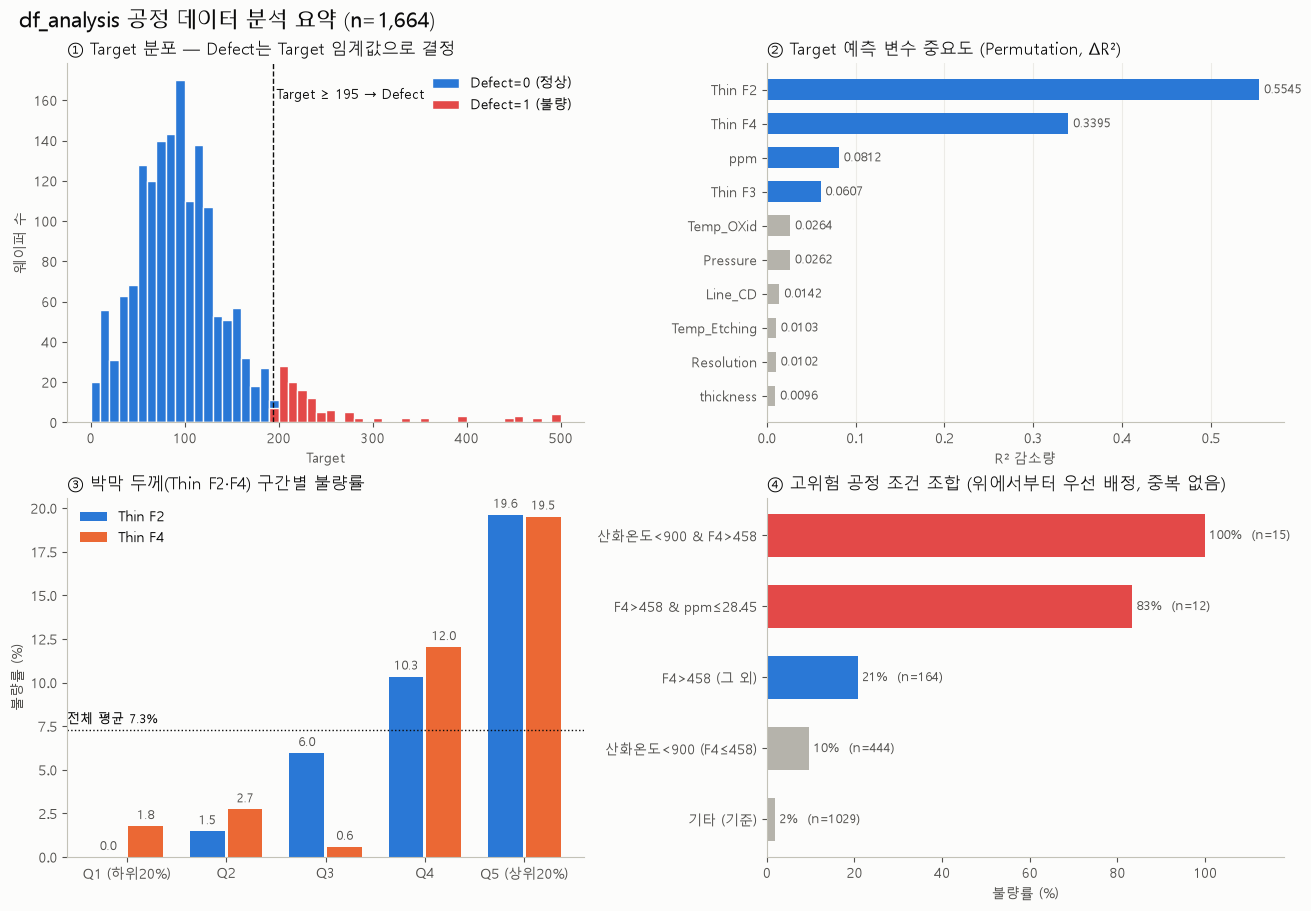

In [21]:
import os
import matplotlib.pyplot as plt
%matplotlib inline

plt.rcParams.update({'font.family': 'Malgun Gothic', 'axes.unicode_minus': False, 'font.size': 10,
                     'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': '#52514e', 'xtick.color': '#52514e',
                     'ytick.color': '#52514e', 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
                     'axes.formatter.useoffset': False, 'axes.formatter.limits': (-99, 99)})   # 축 지수 표기 끄기
BLUE, ORANGE, RED, GRAY, INK = '#2a78d6', '#eb6834', '#e34948', '#b5b3ab', '#0b0b0b'

fig, ax = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
fig.suptitle('df_analysis 공정 데이터 분석 요약 (n=1,664)', fontsize=15, color=INK, x=0.01, ha='left')

# ① Target 분포
a = ax[0, 0]; bins = np.arange(0, 505, 10)
a.hist(df.loc[yd == 0, 'Target'], bins=bins, color=BLUE, edgecolor='#fcfcfb', label='Defect=0 (정상)')
a.hist(df.loc[yd == 1, 'Target'], bins=bins, color=RED, edgecolor='#fcfcfb', label='Defect=1 (불량)')
a.axvline(194, color=INK, lw=1, ls='--')
a.text(198, a.get_ylim()[1] * .9, 'Target ≥ 195 → Defect', color=INK)
a.set_title('① Target 분포 — Defect는 Target 임계값으로 결정', loc='left', color=INK)
a.set_xlabel('Target'); a.set_ylabel('웨이퍼 수'); a.legend(frameon=False)

# ② 변수 중요도
a = ax[0, 1]; top = imp.head(10)[::-1]
a.barh(top.index, top.values, color=[BLUE if v > 0.05 else GRAY for v in top.values], height=0.6)
for i, v in enumerate(top.values):
    a.text(v + 0.005, i, f'{v:,.4f}', va='center', color='#52514e', fontsize=9)
a.set_title('② Target 예측 변수 중요도 (Permutation, ΔR²)', loc='left', color=INK)
a.set_xlabel('R² 감소량'); a.grid(axis='x', color='#ecebe7'); a.set_axisbelow(True)

# ③ Thin F2 / F4 5분위 불량률
a = ax[1, 0]; w = 0.38; x = np.arange(5)
for k, (c, col) in enumerate([('Thin F2', BLUE), ('Thin F4', ORANGE)]):
    r = df.groupby(pd.qcut(df[c], 5), observed=True)['Defect'].mean() * 100
    a.bar(x + (k - .5) * w, r.values, w - 0.03, color=col, label=c)
    for xi, v in zip(x + (k - .5) * w, r.values):
        a.text(xi, v + .4, f'{v:.1f}', ha='center', fontsize=8.5, color='#52514e')
a.axhline(yd.mean() * 100, color=INK, lw=1, ls=':')
a.text(-0.6, yd.mean() * 100 + .4, '전체 평균 7.3%', ha='left', fontsize=9)
a.set_xticks(x, ['Q1 (하위20%)', 'Q2', 'Q3', 'Q4', 'Q5 (상위20%)'])
a.set_title('③ 박막 두께(Thin F2·F4) 구간별 불량률', loc='left', color=INK)
a.set_ylabel('불량률 (%)'); a.legend(frameon=False)

# ④ 고위험 조건 조합
a = ax[1, 1]; g = seg_table.sort_values('불량률')
a.barh(g.index, g['불량률'] * 100, height=0.6,
       color=[RED if m > .5 else (BLUE if m > .1 else GRAY) for m in g['불량률']])
for i, (m, n) in enumerate(zip(g['불량률'], g['n'])):
    a.text(m * 100 + 1, i, f'{m*100:.0f}%  (n={n})', va='center', fontsize=9, color='#52514e')
a.set_xlim(0, 118); a.set_xlabel('불량률 (%)')
a.set_title('④ 고위험 공정 조건 조합 (위에서부터 우선 배정, 중복 없음)', loc='left', color=INK)

os.makedirs('output', exist_ok=True)
fig.savefig('output/analysis_summary.png', dpi=150)
plt.show()

## 결론 요약
- `Defect = Target ≥ 195` (파생 라벨) / `두께정상 = thickness ≥ 700` / `CD정상 = 22 ≤ Line_CD ≤ 55`
- Target 예측: HistGB R² ≈ 0.73 · Defect 분류(Target 제외): RandomForest ROC-AUC ≈ 0.98
- 핵심 인자: **Thin F2, Thin F4** ≫ ppm, Thin F3, Temp_OXid, Pressure
- 고위험 조건: **산화온도 < 900°C & Thin F4 > 458 → 불량률 100% (15/15)**, Thin F4 > 458 & ppm ≤ 28.45 → 83%
- Dry 산화 불량률(9.5%)이 Wet(4.2%)의 2배 이상, Flux90s 비정상 저값 웨이퍼 불량률 43%
- 관측 데이터 기반 상관관계이므로 인과 확정은 DOE 검증 필요